# 기업 부도 예측: 분석 노트북

재무비율로 기업의 1년 내 부도 가능성(PD)을 예측하는 과정을 순서대로 따라간다.
최종 결과 숫자와 그림은 `python run_pipeline.py`가 만들고, 이 노트북은 **왜 그렇게 했는지**를 보여준다.

1. 데이터 점검: 범위를 벗어난 값과 중복 변수
2. 하이퍼파라미터 튜닝
3. 결과 읽기: 모델 비교, 보정, 위험등급, 설명, 예상손실
4. 리스크 관리로 확장: 모형 검증, 신용 VaR, 스트레스 테스트

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from default_risk import config, data, models

pd.set_option("display.width", 140, "display.max_columns", 20)
raw = data.load_raw()
print(raw.shape, "| 부도", int(raw[config.TARGET].sum()), f"({raw[config.TARGET].mean():.2%})")

(6819, 96) | 부도 220 (3.23%)


## 1. 데이터 점검

### 1-1. 0~1이어야 할 비율에 60만~100억 값이 섞여 있다

데이터 설명에는 모든 변수가 0~1로 정규화돼 있다고 되어 있다. 실제로 확인해 보면 24개 변수에서 범위를 벗어난 값이 나온다.

In [2]:
X_raw = raw.drop(columns=config.TARGET)
mask = data.find_out_of_range(X_raw)
oor = mask.sum()
oor = oor[oor > 0].sort_values(ascending=False)
summary = pd.DataFrame({
    "범위밖 개수": oor,
    "범위밖 비율": (oor / len(raw)).map("{:.1%}".format),
    "0~1 구간 최댓값": [X_raw.loc[~mask[c], c].max() for c in oor.index],
    "범위밖 최솟값": [X_raw.loc[mask[c], c].min() for c in oor.index],
})
summary

,범위밖 개수,범위밖 비율,0~1 구간 최댓값,범위밖 최솟값
Total Asset Growth Rate,6017,88.2%,1.0,5.830000e+05
Cash Turnover Rate,4239,62.2%,1.0,6.610000e+05
Research and development expense rate,4033,59.1%,1.0,1.700000e+07
Inventory Turnover Rate (times),2946,43.2%,1.0,1.910000e+07
Quick Asset Turnover Rate,2383,34.9%,1.0,8.820000e+06
Operating Expense Rate,2282,33.5%,1.0,6.040000e+05
Current Asset Turnover Rate,1234,18.1%,1.0,3.780000e+06
Fixed Assets Turnover Frequency,1228,18.0%,1.0,1.510000e+07
Interest-bearing debt interest rate,221,3.2%,1.0,1.000000e+06
Long-term Liability to Current Assets,109,1.6%,1.0,1.250000e+07


두 구간 사이가 완전히 비어 있다. 0~1 구간의 최댓값은 1 이하인데 범위 밖 값은 가장 작은 것도 수십만 이상이다.
조금 큰 이상치가 아니라 **정규화가 되지 않은 값이 그대로 섞인 것**으로 봐야 한다. 같은 척도로 비교할 수 없으므로 결측으로 처리했다.

그런데 이 '범위 밖' 여부가 부도와 관련이 있다.

In [3]:
y = raw[config.TARGET]
rows = []
for c in oor.index[:8]:
    m = mask[c]
    rows.append({"변수": c, "범위밖 기업 부도율": y[m].mean(), "정상범위 기업 부도율": y[~m].mean()})
pd.DataFrame(rows).set_index("변수").style.format("{:.1%}")

,범위밖 기업 부도율,정상범위 기업 부도율
변수,,
Total Asset Growth Rate,3.5%,1.0%
Cash Turnover Rate,4.3%,1.4%
Research and development expense rate,3.0%,3.6%
Inventory Turnover Rate (times),4.0%,2.6%
Quick Asset Turnover Rate,4.1%,2.8%
Operating Expense Rate,2.9%,3.4%
Current Asset Turnover Rate,4.3%,3.0%
Fixed Assets Turnover Frequency,6.8%,2.4%


재무적 의미가 아니라 **데이터 처리 과정의 흔적**이 부도율과 연결돼 있다.
이 흔적만으로 만든 모델의 AUROC가 0.70이다(아래 3절 표). 모델에 넣으면 점수는 조금 오를 수 있지만,
왜 맞히는지 설명할 수 없고 데이터 처리 방식이 바뀌면 무너질 신호라서 쓰지 않았다.

### 1-2. 같은 정보를 담은 변수

값이 완전히 같거나, 하나가 다른 하나를 1에서 뺀 값(부채비율 ↔ 자기자본비율)인 변수 쌍을 지웠다.
값이 하나뿐인 `Net Income Flag`도 지웠다.

In [4]:
X, y, report = data.clean(raw)
report.summary()

{'rows': 6819,
 'raw_features': 95,
 'features_after_cleaning': 91,
 'columns_with_out_of_range_values': 24,
 'out_of_range_cells': 24940,
 'dropped_constant': ['Net Income Flag'],
 'dropped_duplicate': {'Net worth/Assets': 'Debt ratio %',
  'Current Liability to Liability': 'Current Liabilities/Liability',
  'Current Liability to Equity': 'Current Liabilities/Equity'}}

## 2. 하이퍼파라미터 튜닝

학습 데이터(80%)만으로 5-fold 교차검증을 해서 골랐다. 평가 데이터(20%)는 최종 확인 전까지 보지 않는다.

In [5]:
idx = np.arange(len(y))
tr, te = train_test_split(idx, test_size=config.TEST_SIZE, stratify=y, random_state=config.SEED)
Xtr, ytr = X.iloc[tr], y.iloc[tr]
cv = StratifiedKFold(5, shuffle=True, random_state=config.SEED)

def cv_auc(model):
    s = cross_val_score(model, Xtr, ytr, cv=cv, scoring="roc_auc")
    return round(s.mean(), 4), round(s.std(), 4)

rows = []
for C in [0.01, 0.03, 0.1, 0.3]:
    rows.append(("Logit", f"C={C}", *cv_auc(models.make_logit(C=C))))
for sel in [0.02, 0.05, 0.1]:
    rows.append(("Logit-10", f"select_C={sel}", *cv_auc(models.make_sparse_logit(select_C=sel))))
for depth in [2, 3, 4]:
    for n in [300, 600]:
        rows.append(("XGBoost", f"depth={depth}, n={n}", *cv_auc(models.make_xgb(max_depth=depth, n_estimators=n))))
pd.DataFrame(rows, columns=["모델", "설정", "AUROC 평균", "AUROC 표준편차"])

,모델,설정,AUROC 평균,AUROC 표준편차
0,Logit,C=0.01,0.9375,0.0170
1,Logit,C=0.03,0.9381,0.0170
2,Logit,C=0.1,0.9386,0.0175
3,Logit,C=0.3,0.9381,0.0188
4,Logit-10,select_C=0.02,0.9255,0.0194
5,Logit-10,select_C=0.05,0.9315,0.0196
6,Logit-10,select_C=0.1,0.9293,0.0195
7,XGBoost,"depth=2, n=300",0.9430,0.0204
8,XGBoost,"depth=2, n=600",0.9422,0.0207
9,XGBoost,"depth=3, n=300",0.9437,0.0218


평균이 높은 축에 드는 설정을 골랐다: Logit `C=0.1`, Logit-10 `select_C=0.05`, XGBoost `depth=3, n=300`.
같은 모델 안에서 설정 간 차이가 fold 간 표준편차(약 0.02)보다 훨씬 작아서, 튜닝으로 얻는 이득은 크지 않다.

## 3. 결과 읽기

아래는 `run_pipeline.py`가 저장한 결과다.

In [6]:
res = json.loads((config.REPORT_DIR / "metrics.json").read_text(encoding="utf-8"))
fig = lambda name: display(Image(filename=str(config.FIG_DIR / name)))
cv_tbl = pd.DataFrame({m: {k: f"{v['mean']:.3f} ± {v['std']:.3f}" for k, v in d.items()} for m, d in res["cv"].items()}).T
cv_tbl

,AUROC,AR,KS,PR-AUC,Brier,Recall@10%
Logit-10,0.927 ± 0.023,0.854 ± 0.045,0.738 ± 0.059,0.435 ± 0.069,0.024 ± 0.002,0.731 ± 0.079
Logit,0.936 ± 0.019,0.871 ± 0.037,0.774 ± 0.026,0.451 ± 0.067,0.023 ± 0.002,0.744 ± 0.080
XGBoost,0.942 ± 0.020,0.884 ± 0.039,0.779 ± 0.051,0.459 ± 0.089,0.023 ± 0.002,0.777 ± 0.075


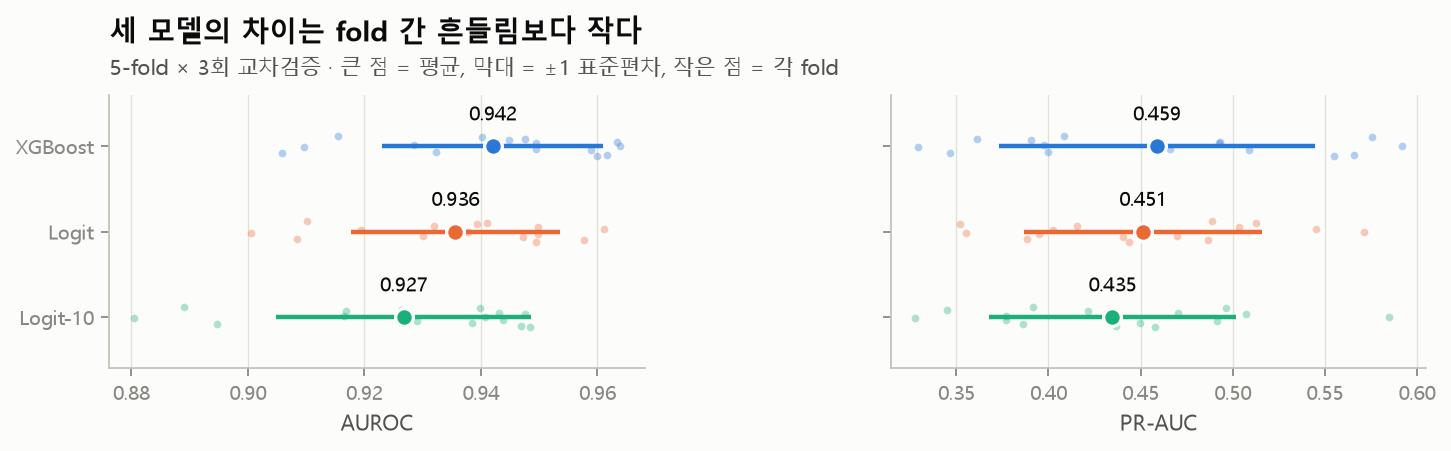

In [7]:
fig("02_cv_comparison.png")

XGBoost가 평균은 가장 높지만, 세 모델의 차이가 fold 간 흔들림보다 작다.
변수 10개짜리 로지스틱 회귀(Logit-10)도 AUROC 0.93 수준이라, **설명이 필요한 실무에서는 단순한 모델도 충분한 후보**다.

In [8]:
pd.DataFrame(res["sensitivity_out_of_range"]).T

,Logit,XGBoost
원래 값 그대로,0.933506,0.942152
결측 처리 (채택),0.935602,0.942056
결측 처리 + 범위밖 표시 변수,0.934394,0.942251
범위밖 표시 변수만,0.701816,0.696384


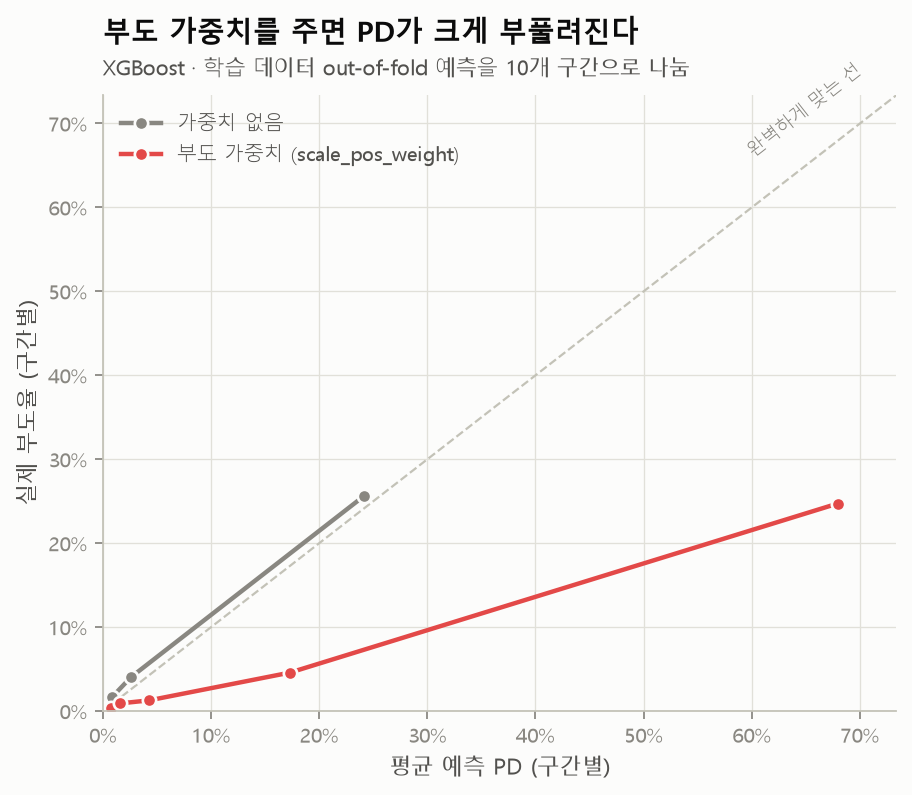

,AUROC,Brier,mean_predicted_pd,observed_default_rate,ratio
XGBoost,0.942731,0.022504,0.028592,0.032264,0.886179
XGBoost (부도 가중치),0.935810,0.044915,0.093044,0.032264,2.883838
Logit,0.938034,0.023290,0.032655,0.032264,1.012115
Logit (부도 가중치),0.933792,0.084585,0.168253,0.032264,5.214890


In [9]:
fig("04_calibration.png")
pd.DataFrame(res["calibration_oof"]).T[["AUROC", "Brier", "mean_predicted_pd", "observed_default_rate", "ratio"]]

불균형 데이터에서 흔히 쓰는 '부도 가중치'를 주면 AUROC는 오히려 조금 낮아지고,
평균 예측 PD가 실제 부도율의 3~5배로 부풀려진다. 순위만 볼 때는 티가 안 나지만 PD를 손실 계산에 쓰면 그대로 손실 과대추정으로 이어진다.

,AUROC,AR,KS,PR-AUC,Brier,Recall@10%,AUROC_CI
Logit-10,0.94697,0.893939,0.781818,0.492077,0.021727,0.840909,0.919 ~ 0.971
Logit,0.954356,0.908712,0.829545,0.550742,0.020667,0.840909,0.925 ~ 0.977
XGBoost,0.961433,0.922865,0.795455,0.553652,0.020368,0.795455,0.942 ~ 0.978


,diff,ci_low,ci_high
XGBoost - Logit-10,0.014463,-0.004003,0.038351
XGBoost - Logit,0.007076,-0.013994,0.036370


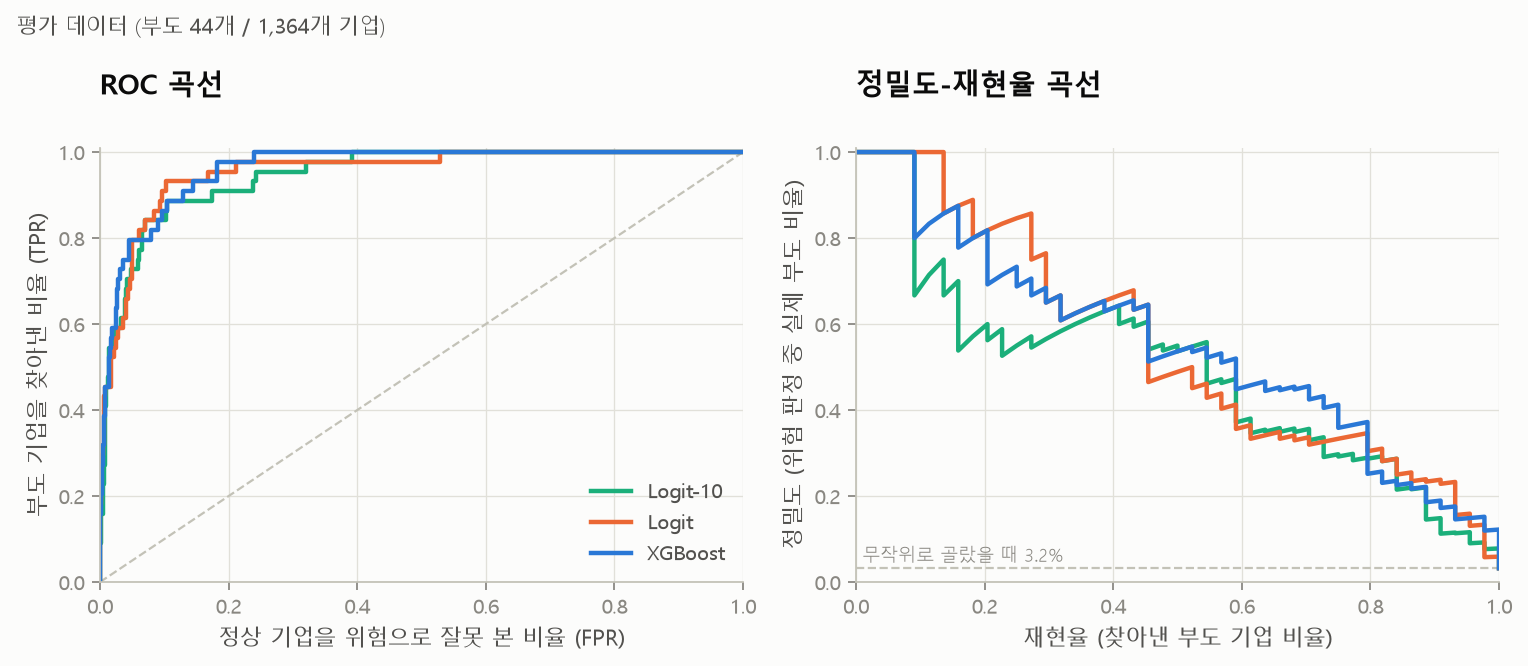

In [10]:
test = pd.DataFrame(res["test"]).T
test["AUROC_CI"] = test["AUROC_CI"].map(lambda v: f"{v[0]:.3f} ~ {v[1]:.3f}")
display(test)
display(pd.DataFrame(res["test_diff"]).T)
fig("03_roc_pr.png")

평가 데이터에는 부도 기업이 44개뿐이라 AUROC 신뢰구간이 ±0.02~0.03 정도로 넓다.
같은 표본으로 모델 간 차이를 부트스트랩해 보면 신뢰구간이 0을 포함한다. **평가 데이터만으로 어느 모델이 낫다고 말할 수 없다.**

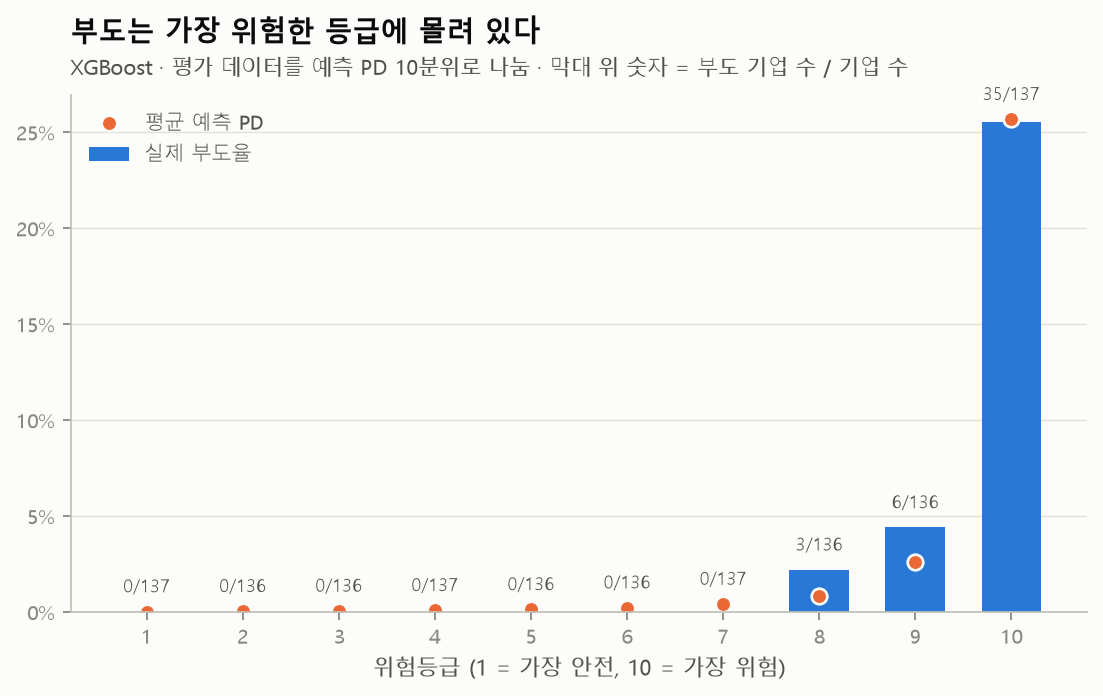

,기업수,부도기업수,실제부도율,평균예측PD
grade,,,,
1,137,0,0.000000,0.000292
2,136,0,0.000000,0.000446
3,136,0,0.000000,0.000628
4,137,0,0.000000,0.000916
5,136,0,0.000000,0.001410
6,136,0,0.000000,0.002314
7,137,0,0.000000,0.004213
8,136,3,0.022059,0.008626
9,136,6,0.044118,0.025927


In [11]:
fig("05_risk_grades.png")
pd.DataFrame(res["grades"]["table"]).set_index("grade")

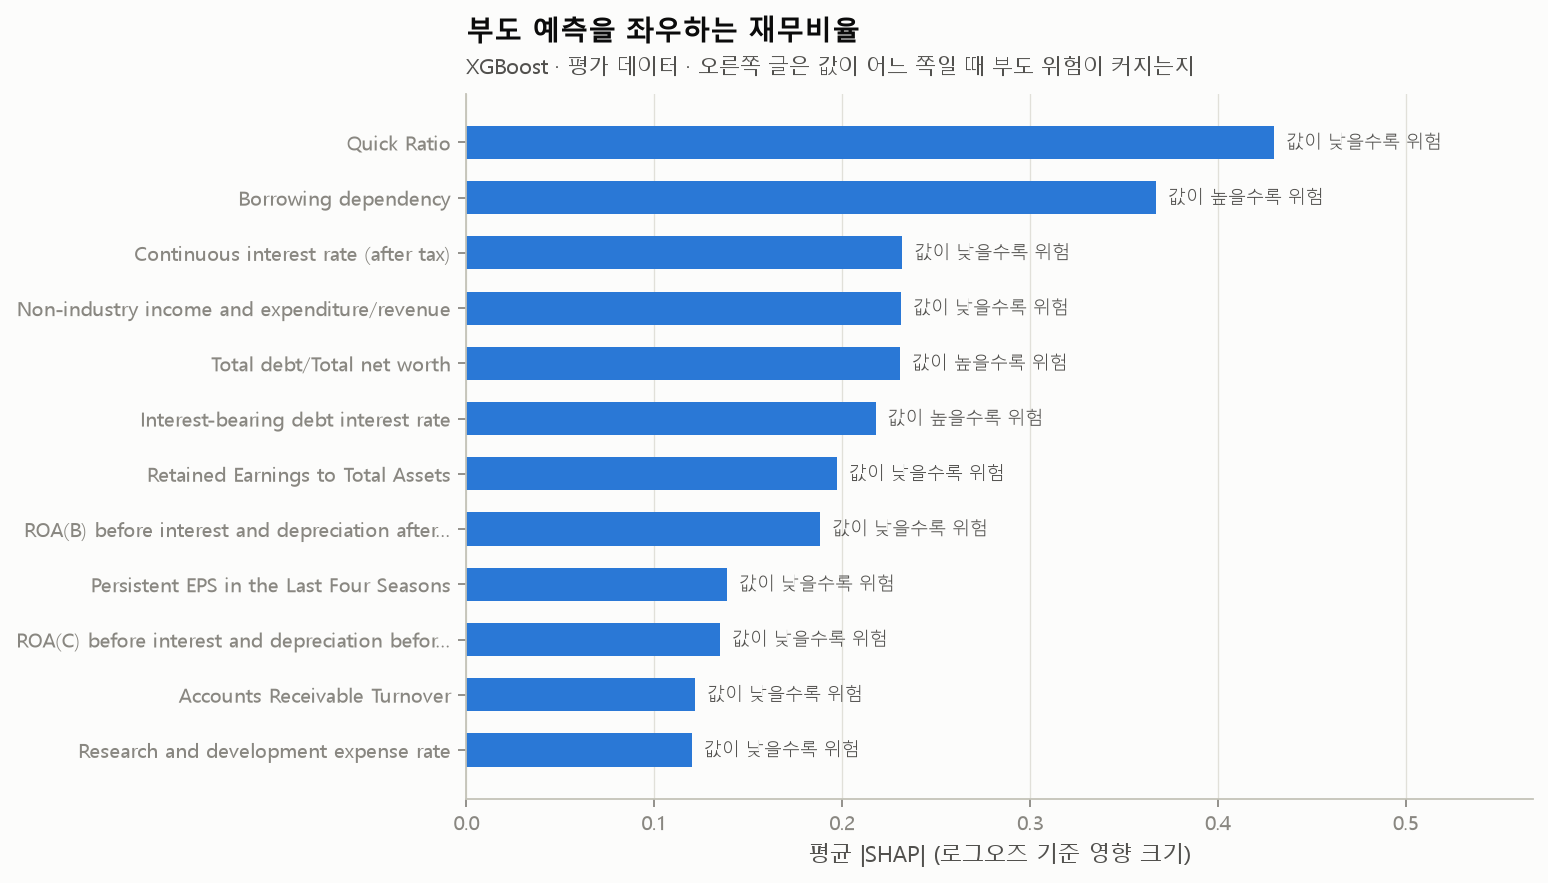

Logit-10이 고른 변수: ['Borrowing dependency', 'ROA(B) before interest and depreciation after tax', 'Retained Earnings to Total Assets', 'Liability-Assets Flag', 'Continuous interest rate (after tax)', 'Interest-bearing debt interest rate', 'Cash/Total Assets', 'Net Value Growth Rate', 'Current Liabilities/Equity', "Net Income to Stockholder's Equity"]
SHAP 상위 10개와 겹침: ['Borrowing dependency', 'Continuous interest rate (after tax)', 'Interest-bearing debt interest rate', 'ROA(B) before interest and depreciation after tax', 'Retained Earnings to Total Assets']


In [12]:
fig("06_shap_importance.png")
print("Logit-10이 고른 변수:", list(res["logit10"]["features"]))
print("SHAP 상위 10개와 겹침:", res["logit10"]["overlap_with_shap_top10"])

두 모델이 따로 학습했는데도 차입 의존도, 이자부채 이자율, 이익잉여금/총자산, ROA 같은 변수를 공통으로 중요하게 본다.
방향도 재무적 상식과 맞는다(빚이 많을수록, 수익성이 낮을수록 위험).

In [13]:
print(res["missed"]["caught"], "개 잡아냄 /", res["missed"]["missed"], "개 놓침")
pd.DataFrame(res["missed"]["medians"])

35 개 잡아냄 / 9 개 놓침


,잡아낸 부도,놓친 부도,정상 기업
Quick Ratio,0.002566,0.003845,0.007765
Borrowing dependency,0.383343,0.376490,0.372488
Continuous interest rate (after tax),0.781277,0.781567,0.781647


상위 10%로 위험 판정했을 때 놓친 부도 기업은 차입 의존도 같은 빚 지표의 중앙값이 잡아낸 부도 기업보다 정상 기업에 가깝다(위 표).
재무제표만으로는 드러나지 않는 부도가 있다는 뜻이고, 주가 기반의 EDF나 뉴스 같은 다른 정보가 필요한 지점이다.

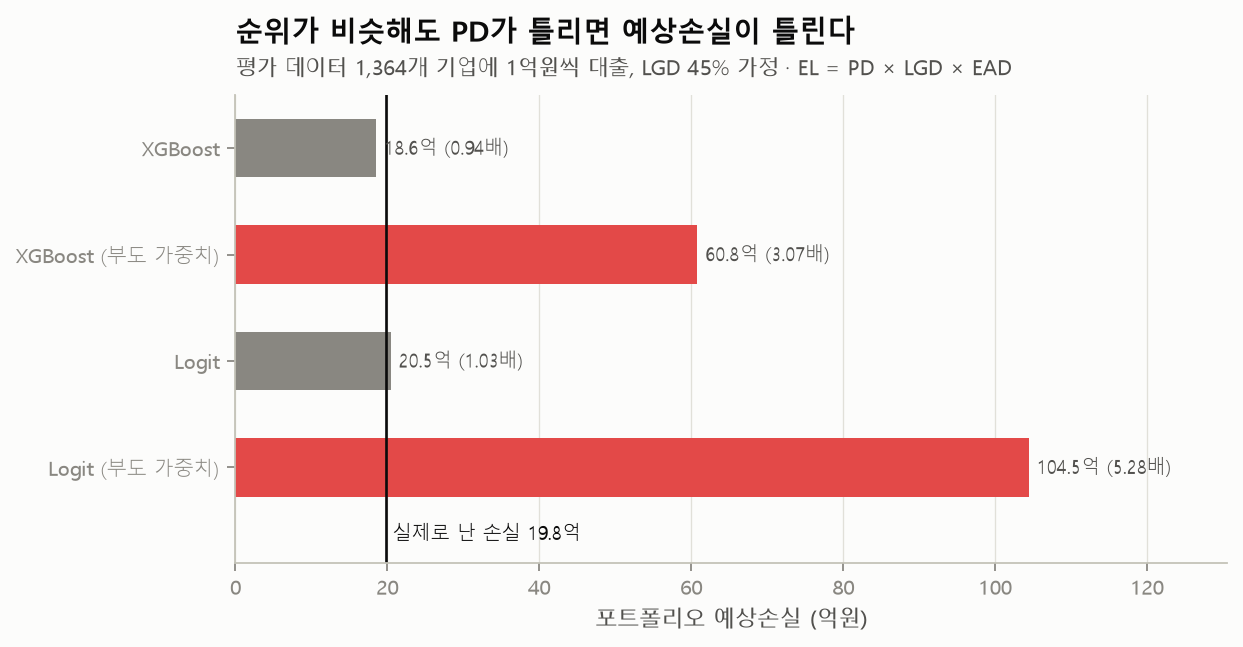

,exposure,expected_loss,realized_loss,ratio
XGBoost,1364.0,18.574268,19.8,0.938094
XGBoost (부도 가중치),1364.0,60.820976,19.8,3.071766
Logit,1364.0,20.455761,19.8,1.033119
Logit (부도 가중치),1364.0,104.457363,19.8,5.275624


In [14]:
fig("07_expected_loss.png")
pd.DataFrame(res["expected_loss"]).T

## 4. 리스크 관리로 확장

### 4-1. 모형 검증과 재보정

예측 PD 구간으로 고정한 9개 등급(마스터 스케일)마다 Jeffreys 단측검정으로 PD 과소추정 여부를 본다.

개발 데이터 · 보정 전: HL p = 0.054, 판정 {'적합': 7, '경고': 1, '주의': 1}, 평균 PD 2.86% / 실제 3.23%
평가 데이터 · 보정 전: HL p = 0.641, 판정 {'적합': 9}, 평균 PD 3.03% / 실제 3.23%
평가 데이터 · 보정 후: HL p = 0.886, 판정 {'적합': 9}, 평균 PD 3.39% / 실제 3.23%
Platt 보정: {'slope': 0.8982348724387914, 'intercept': -0.011383732181942333} | PSI: 0.0064


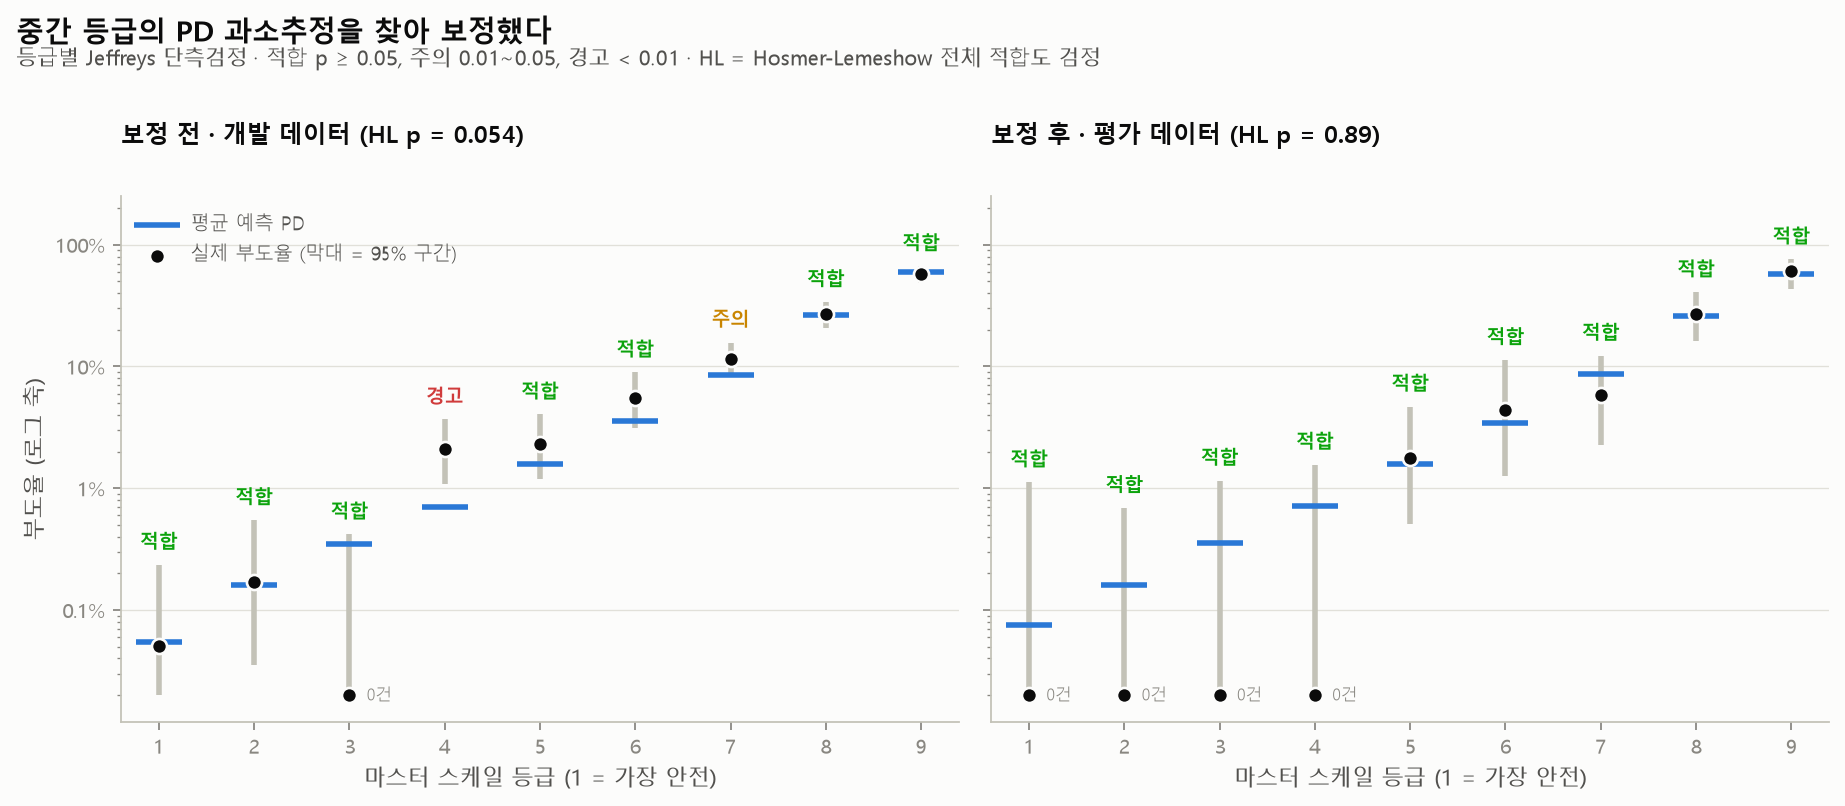

,PD 구간,기업수,부도수,평균예측PD,실제부도율,이항검정 p,Jeffreys p,판정
등급,,,,,,,,
1,0% ~ 0.1%,1981,1,0.000550,0.000505,0.663628,0.463864,적합
2,0.1% ~ 0.25%,1169,2,0.001592,0.001711,0.555183,0.409909,적합
3,0.25% ~ 0.5%,600,0,0.003512,0.000000,1.000000,0.960126,적합
4,0.5% ~ 1%,479,10,0.007071,0.020877,0.002528,0.001385,경고
5,1% ~ 2.5%,435,10,0.015675,0.022989,0.149952,0.113637,적합
6,2.5% ~ 5%,237,13,0.035441,0.054852,0.081211,0.060577,적합
7,5% ~ 15%,277,32,0.085327,0.115523,0.050011,0.040667,주의
8,15% ~ 40%,168,45,0.262341,0.267857,0.464675,0.430144,적합
9,40% ~ 100%,109,63,0.592632,0.577982,0.660392,0.624200,적합


In [15]:
v = res["validation"]
for k in ["개발 데이터 · 보정 전", "평가 데이터 · 보정 전", "평가 데이터 · 보정 후"]:
    hl = v[k]["hosmer_lemeshow"]
    print(f"{k}: HL p = {hl['p_value']:.3f}, 판정 {v[k]['verdicts']}, 평균 PD {v[k]['mean_pd']:.2%} / 실제 {v[k]['default_rate']:.2%}")
print("Platt 보정:", v["calibrator"], "| PSI:", round(v["psi_dev_vs_test"], 4))
fig("08_validation.png")
pd.DataFrame(v["개발 데이터 · 보정 전"]["table"]).set_index("등급")

개발 데이터에서 일부 중간 등급이 '주의'나 '경고'로 나왔다(위 표의 판정 열). PD를 실제보다 낮게 본다는 뜻이고, 이대로 쓰면 손실과 자본이 과소추정된다.
개발 데이터의 out-of-fold 예측으로만 Platt 보정을 적합해 평가 데이터에 적용하고, 평가 데이터에서 다시 검정했다.

### 4-2. 신용 VaR

바젤 1요인 모형으로 1년 손실 분포를 10만 번 시뮬레이션하고, 같은 모형의 해석해(IRB 공식)와 비교한다.

{'EL': 20.8, 'VaR 99%': 58.9, 'ES 99%': 71.9, 'VaR 99.9%': 88.2, 'ES 99.9%': 105.3, 'UL (VaR 99.9% - EL)': 67.4, 'IRB UL (analytic)': 68.1, 'exposure': 1364.0, 'realized_loss': 19.8}
다른 시드의 UL: [68.3, 68.3, 68.8, 71.0, 70.6]


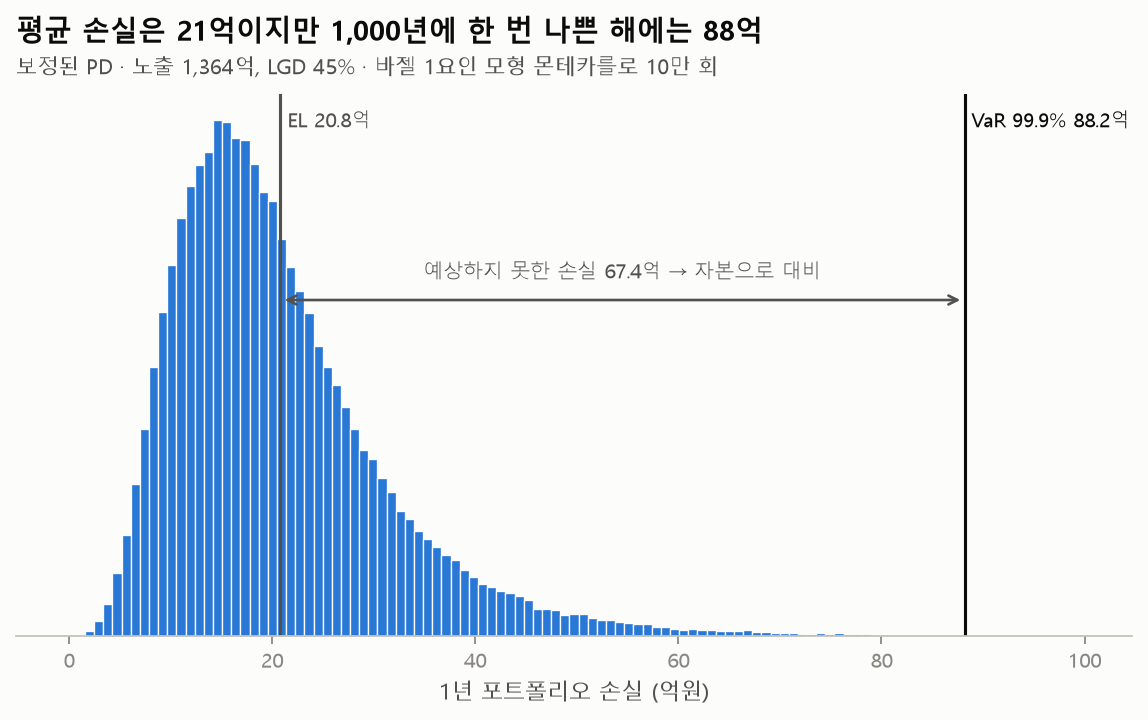

In [16]:
cv_ = res["credit_var"]
print({k: round(x, 1) for k, x in cv_.items() if isinstance(x, float)})
print("다른 시드의 UL:", [round(x, 1) for x in cv_["UL_other_seeds"]])
fig("09_loss_distribution.png")

### 4-3. 스트레스 테스트

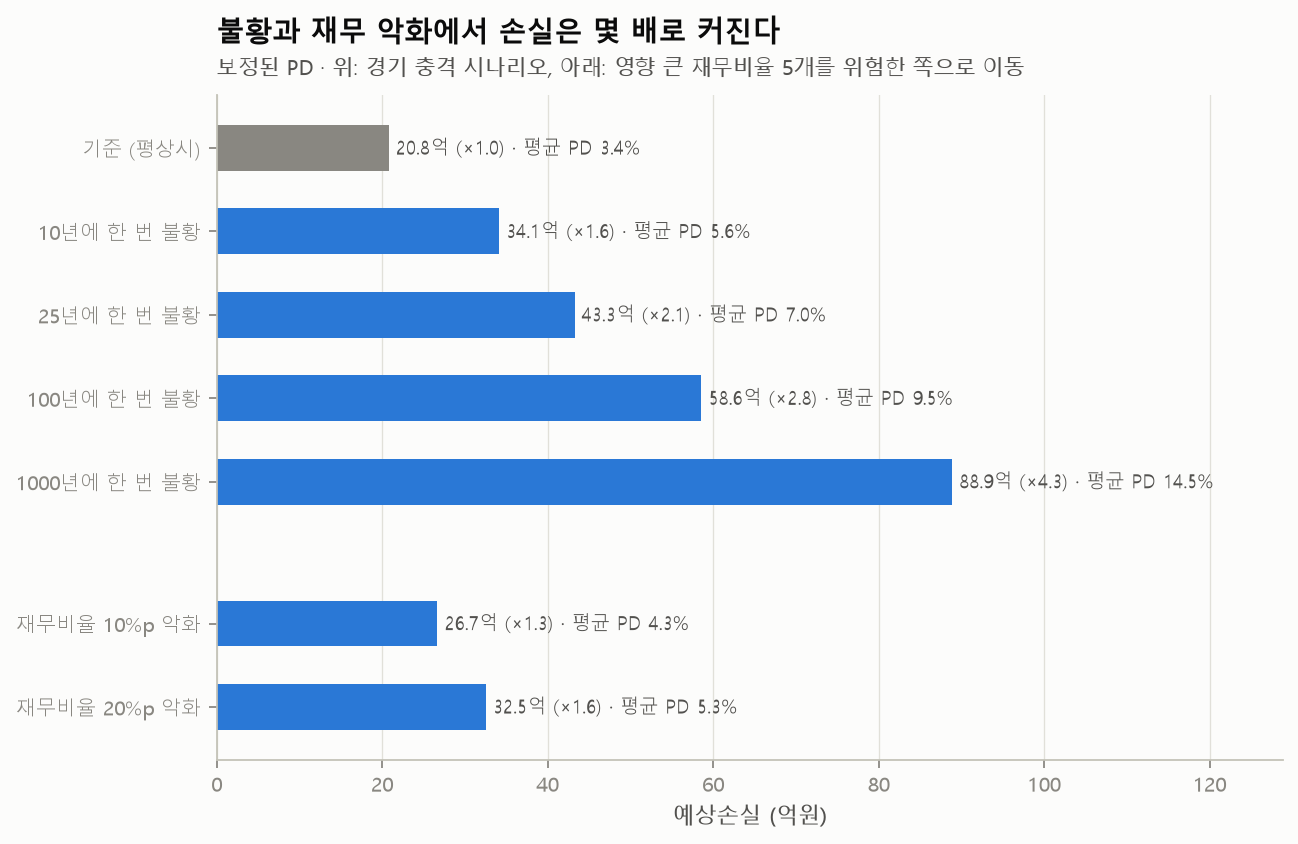

,평균PD,예상손실
시나리오,,
기준 (평상시),0.033882,20.796500
10년에 한 번 불황,0.055595,34.124158
25년에 한 번 불황,0.070473,43.256305
100년에 한 번 불황,0.095437,58.579363
1000년에 한 번 불황,0.144793,88.874006
재무비율 10%p 악화,0.043485,26.690948
재무비율 20%p 악화,0.053009,32.537198


{'재무비율 10%p 악화': {'share_grade_8_9': 0.07917888563049853,
  'psi_vs_base': 0.027794630923871244},
 '재무비율 20%p 악화': {'share_grade_8_9': 0.10557184750733138,
  'psi_vs_base': 0.11693702458705446},
 '기준 (평상시)': {'share_grade_8_9': 0.0593841642228739, 'psi_vs_base': 0.0}}

In [17]:
fig("10_stress.png")
display(pd.DataFrame(res["stress"]["table"]).set_index("시나리오"))
res["stress"]["migration"]